# Explaining a regression model

This notebook explains a random forest that predicts the progression of diabetes one year ahead from age, sex, body mass index, blood pressure and six blood measurements (the diabetes dataset bundled with scikit-learn; the features are standardized). It shows:

1. counterfactuals with a desired outcome — a lower predicted progression;
2. immutable features and counterfactuals built from the rules;
3. the fidelity of the surrogate tree and the adaptive neighborhood;
4. the evaluation of the counterfactuals of many instances.

Requirements: `pip install "nife[examples]"`.

In [1]:
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

from nife.counterfactual import TreeCounterfactualExplainer
from nife.counterfactual.tree import fidelity_table

## Data and model

In [2]:
X, y = load_diabetes(return_X_y=True, as_frame=True)
model = RandomForestRegressor(random_state=0)
mae = -cross_val_score(model, X, y, scoring="neg_mean_absolute_error").mean()
print(f"MAE (5-fold cross-validation): {mae:.1f}; target from {y.min():.0f} to {y.max():.0f}")
model.fit(X, y)
X.head()

MAE (5-fold cross-validation): 47.0; target from 25 to 346


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


## 1. A desired outcome

In regression, a counterfactual changes the prediction by more than `tolerance` (5% by default). `desired="lower"` keeps only those that lower it; `"higher"` and intervals such as `(None, 100)` are also accepted.

In [3]:
explainer = TreeCounterfactualExplainer(model, X, mode="regression", categorical_features=["sex"], random_state=0)
explanation = explainer.explain(X.iloc[0], desired="lower")
explanation

TreeCounterfactualExplanation (regression) of an instance predicted 175.48, desired 'lower'
  decision path: bmi <= 0.06765 and bp <= 0.02359 and s5 <= 0.02131 and bmi <= 0.06568 and bp > 0.004208
  relevant features: bmi, bp, s5, s1
  crossed rule: bp > 0.004208 -> bp <= 0.004208
  counterfactuals: 175 (data: 175)
  closest: distance 0.054, 8 changed features, predicted 149.65
  fidelity: instance agreement True, local fidelity 0.14 (neighborhood: around the instance, scale 0.25)

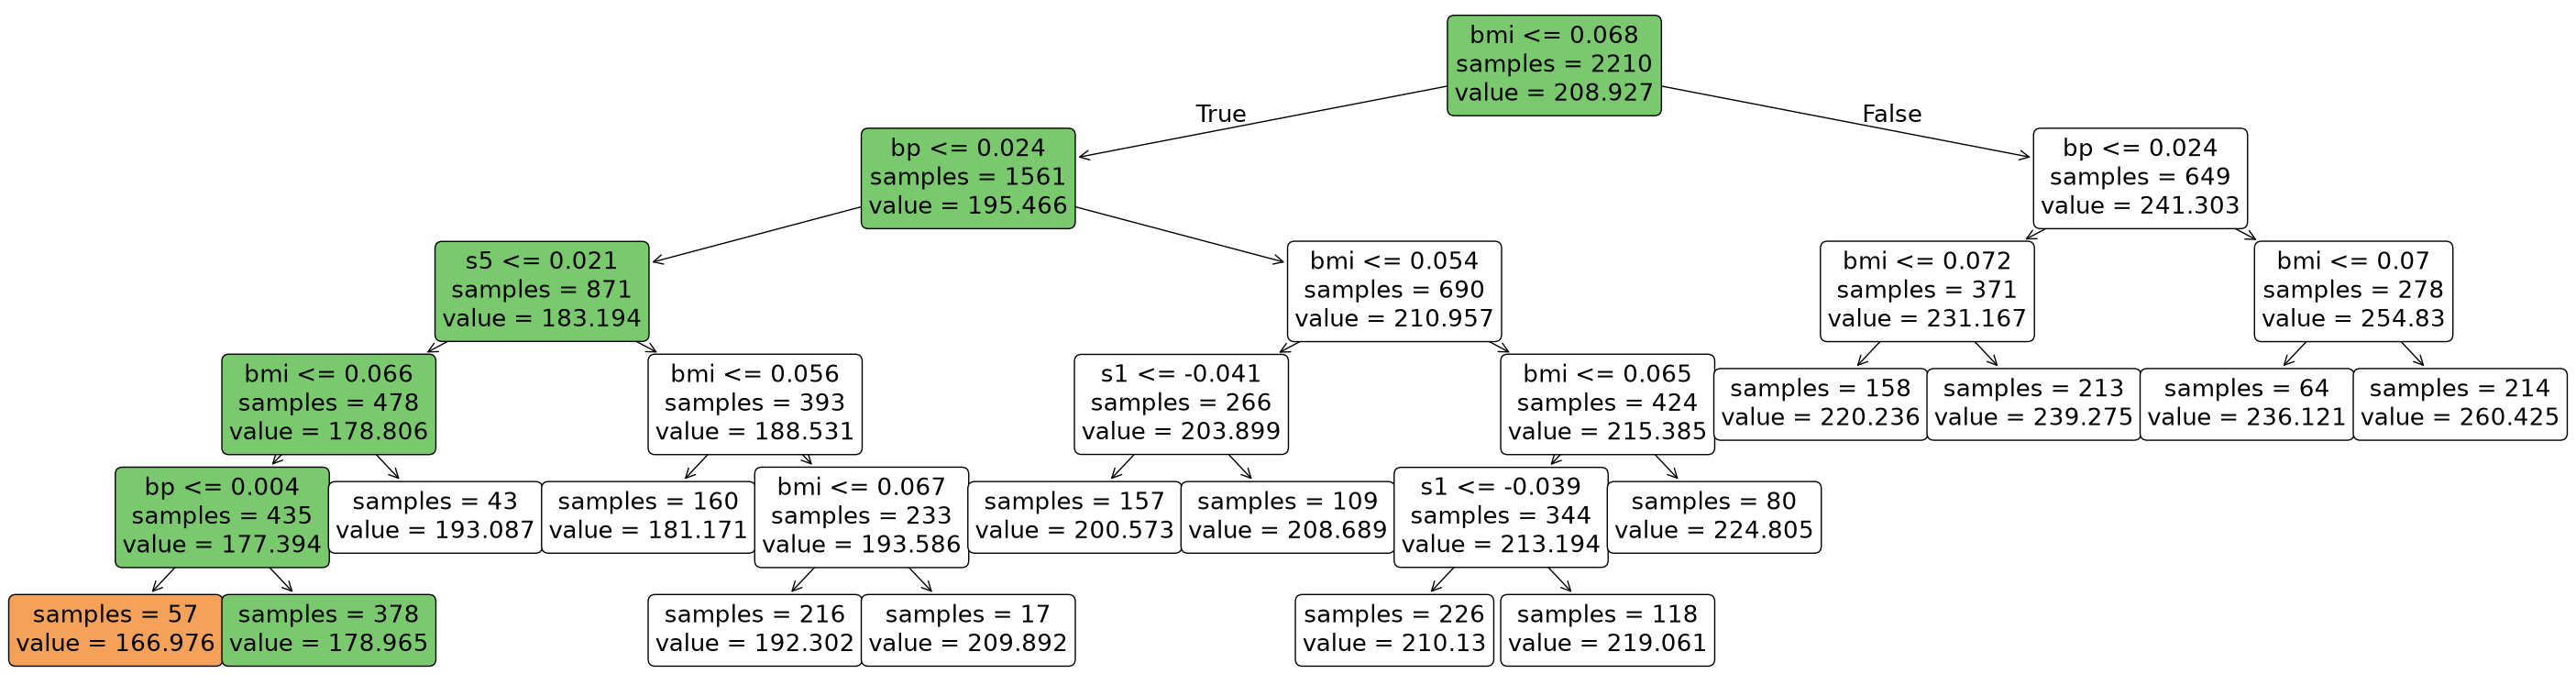

In [4]:
explanation.plot_tree();

In [5]:
explanation.counterfactuals.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,prediction,source,distance,changed_features
0,0.085299,0.05068,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,149.65,data,0.053726,8
1,0.041708,0.05068,0.061696,-0.040099,-0.013953,0.006202,-0.028674,-0.002592,-0.014960,0.011349,124.14,data,0.080078,7
2,0.034443,0.05068,0.028284,-0.033213,-0.045599,-0.009769,-0.050764,-0.002592,-0.059471,-0.021788,144.53,data,0.080149,8
3,0.038076,0.05068,-0.013751,-0.015999,-0.035968,-0.021982,-0.013948,-0.002592,-0.025953,-0.001078,90.68,data,0.085553,7
4,0.038076,0.05068,-0.029918,-0.040099,-0.033216,-0.024174,-0.010266,-0.002592,-0.012909,0.003064,127.96,data,0.099685,7


## 2. Immutable features and counterfactuals from the rules

Age and sex cannot be changed. As `immutable_features`, they keep the instance's values in the perturbed neighborhood — so the tree only splits on the other features — and in every counterfactual. No other patient has exactly the same age, so no example of the data can be a counterfactual; `from_rules=True` builds counterfactuals that change a single feature of the decision path instead (`source` is `"rules"`).

In [6]:
constrained = TreeCounterfactualExplainer(
    model, X, mode="regression", categorical_features=["sex"], immutable_features=["age", "sex"], random_state=0
)
explanation = constrained.explain(X.iloc[0], desired="lower", from_rules=True)
explanation

TreeCounterfactualExplanation (regression) of an instance predicted 175.48, desired 'lower'
  decision path: bmi <= 0.06889 and bp <= 0.02359 and s5 > 0.01495 and bp > -2.402e-05 and bmi > 0.06071
  relevant features: bmi, bp, s5
  crossed rule: bmi > 0.06071 -> bmi <= 0.06071
  counterfactuals: 3 (rules: 3)
  closest: distance 0.007, 1 changed features, predicted 165.84
  fidelity: instance agreement False, local fidelity 0.12 (neighborhood: around the instance, scale 0.5)

In [7]:
explanation.counterfactuals

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,prediction,source,distance,changed_features
0,0.038076,0.05068,0.044451,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,165.84,rules,0.006612,1
1,0.038076,0.05068,0.061696,-0.001091,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,164.66,rules,0.009394,1
2,0.038076,0.05068,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,-0.043984,-0.017646,166.15,rules,0.024602,1


## 3. Fidelity of the surrogate tree

The rules only explain the prediction if the tree agrees with the model around the instance. `explanation.fidelity` reports whether it gives the instance the same outcome and the fraction of its 50 nearest examples on which they agree:

In [8]:
explanation.fidelity

rules                              5
model_prediction              175.48
surrogate_prediction      206.262317
instance_agreement             False
local_fidelity                  0.12
sample_around_instance          True
neighborhood_scale               0.5
dtype: object

By default the neighborhood is adaptive: it starts narrow around the instance and only widens until the tree has rules and a counterfactual is found. `adaptive=False` uses the global sample of the original method. Over 20 instances:

In [9]:
instances = X.sample(20, random_state=0)
rows = {}
for name, adaptive in [("adaptive (default)", True), ("global sample", False)]:
    options = dict(mode="regression", categorical_features=["sex"], adaptive=adaptive, random_state=0)
    _, explanations = TreeCounterfactualExplainer(model, X, **options).explain_many(instances, return_explanations=True)
    fidelity = fidelity_table(explanations)
    rows[name] = fidelity[["rules", "instance_agreement", "local_fidelity"]].mean()
pd.DataFrame(rows)

,adaptive (default),global sample
rules,4.850,4.100
instance_agreement,0.550,0.100
local_fidelity,0.144,0.122


The adaptive neighborhood makes the tree agree with the model at the instance more often, but here the tree rarely stays within 5% of the forest on the nearest examples: a small tree follows a regression forest only roughly. Check the fidelity before reading the rules as the reasons for a prediction; the counterfactuals themselves are always confirmed by the model.

## 4. Evaluating many instances

The counterfactuals from the data are plausible (real examples) but change almost every feature; those from the rules change one feature and are much closer, but are not real examples:

In [10]:
counterfactuals = explainer.explain_many(instances, desired="lower", from_rules=True)
pd.DataFrame(
    {
        source: explainer.evaluate(instances, counterfactuals[counterfactuals["source"] == source], desired="lower")
        for source in ["data", "rules"]
    }
)

,data,rules
coverage,0.500000,0.850000
count,10.900000,2.176471
validity,1.000000,1.000000
proximity,0.182303,0.017585
changed_features,8.817028,1.000000
redundancy,7.715164,0.000000
implausibility,0.000000,0.014076
ynn,0.733677,0.477451
diversity,0.153131,0.048906
